# Was the oil edge real? — Stage 4: removing the futures roll from Brent vs WTI

**Project:** Mean reversion across FX and commodities · **Stage 4 of 4** · Heritage Edge

### Where Stage 3 left us
Brent vs WTI looked like the breakthrough: **14% a year on unseen data, Sharpe 1.50, t = 2.77**, and it passed every stress test. Then two checks pointed at a problem:
* Trades **bunched** just after the monthly contract swaps (28 of 83 entries on days 1–5 of the month, against about 13 expected).
* **All** the profit came from those trades. The 12 trades opened mid-month, away from any swap, averaged **−0.28%**.

### The roll problem, explained simply
A futures contract is an agreement to buy oil in a **specific month**. Each month the nearest contract expires and traders move to the next one. Yahoo's `CL=F` and `BZ=F` glue these contracts end to end, so on the swap day the price can jump — not because oil moved, but because next month's oil has a different price from this month's.

> **Everyday example:** you're comparing two shops' prices for "a loaf of bread". One shop switches from a small loaf to a large loaf on the 20th; the other switches at the end of the month. For ten days the gap between their prices looks huge, then it "snaps back" — but nothing about bread changed.

WTI swaps around the **20th–22nd**, Brent around the **end of the month**. So for about ten days each month the stitched gap between them is distorted, then corrects itself. Our strategy was trading that distortion.

### The fix: spot prices
A **spot price** is the price of oil for delivery *now*. It never swaps contracts, so it has no roll jumps. The US Federal Reserve's free **FRED** database publishes daily spot prices:
* `DCOILWTICO` — WTI spot (Cushing, Oklahoma)
* `DCOILBRENTEU` — Brent spot (Europe)

We run **exactly the Stage 3 strategy** — same settings, same costs, same test period — on spot prices and futures side by side.
* Edge **survives on spot** → the snap-back is real; the roll only inflated it.
* Edge **vanishes on spot** → the Stage 3 result was the roll.

> **Two honest limits:** (1) you can't trade spot prices directly, so this tests whether the gap really snaps back — it isn't a final trading result. (2) The two spot prices may be recorded at different times of day (London vs New York). That can create a fake snap-back of its own, so the **one-day-late** test in section 9 matters more than ever.

## 1. Setup

In [1]:
%pip install -q yfinance pandas numpy matplotlib jinja2

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.figsize"] = (11, 4)

## 2. Settings — identical to Stage 3

The only change: instead of a 75/25 split, the test period starts on a **fixed date** (1 January 2023), so the spot and futures versions are tested on exactly the same days. That's the same period Stages 1–3 used as their test.

In [3]:
START, END   = "2012-01-01", "2026-10-01"
SPLIT_DATE   = "2023-01-01"     # training before, unseen test from here
TRADING_DAYS = 252

COST_BPS = {"Brent": 2.5, "WTI": 2.5}   # one-way, per unit traded (same as Stage 3)

BETA_WINDOW  = 252
Z_WINDOW     = 60
ENTRY_Z      = 2.0
EXIT_Z       = 0.5
TARGET_VOL   = 0.10
MAX_LEVERAGE = 3.0

## 3. Download both versions of the prices

**Spot** comes from FRED. If your computer can't reach FRED, open these two pages, click **Download → CSV**, and save the files next to this notebook as `DCOILBRENTEU.csv` and `DCOILWTICO.csv` — the code uses local files first if they exist:
* https://fred.stlouisfed.org/series/DCOILBRENTEU
* https://fred.stlouisfed.org/series/DCOILWTICO

**Futures** come from Yahoo, as in Stage 3. Both go through the same cleaning (WTI spot also went negative in April 2020, so that day is removed).

In [4]:
def fred_series(series_id):
    local = f"{series_id}.csv"
    src = local if os.path.exists(local) else f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    df = pd.read_csv(src, na_values=".")
    df = df.iloc[:, :2]
    df.columns = ["date", "value"]
    s = pd.Series(df["value"].astype(float).values, index=pd.to_datetime(df["date"]))
    return s.loc[START:END]

def yahoo_close(ticker):
    data = yf.download(ticker, start=START, end=END, progress=False, auto_adjust=False)
    if data.empty:
        raise ValueError(f"No data came back for {ticker}.")
    close = data["Close"]
    return close.iloc[:, 0] if isinstance(close, pd.DataFrame) else close

def clean(close, name):
    s = close.dropna()
    s = s[~s.index.duplicated(keep="last")].sort_index()
    bad = s[s <= 0]
    if len(bad):
        print(f"{name}: removed {len(bad)} day(s) with price <= 0 -> {list(bad.index.date)}")
    return s[s > 0].rename(name)

SOURCES = {
    "Futures (Yahoo)": {"Brent": yahoo_close("BZ=F"),         "WTI": yahoo_close("CL=F")},
    "Spot (FRED)":     {"Brent": fred_series("DCOILBRENTEU"), "WTI": fred_series("DCOILWTICO")},
}

pair_px = {}
for src, legs in SOURCES.items():
    px = pd.concat([clean(legs["Brent"], f"{src} Brent"), clean(legs["WTI"], f"{src} WTI")], axis=1, join="inner")
    px.columns = ["Brent", "WTI"]
    pair_px[src] = px
    print(f"{src}: {len(px)} shared days, {px.index.min().date()} to {px.index.max().date()}")

/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/yfinance/multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
/Library/Frameworks/Python.framework/Versions/3.15/lib/python3.15/site-packages/yfinance/multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsne

Futures (Yahoo) WTI: removed 1 day(s) with price <= 0 -> [datetime.date(2020, 4, 20)]
Futures (Yahoo): 3688 shared days, 2012-01-03 to 2026-09-30
Spot (FRED) WTI: removed 1 day(s) with price <= 0 -> [datetime.date(2020, 4, 20)]
Spot (FRED): 3643 shared days, 2012-01-03 to 2026-10-01


## 4. See the roll with your own eyes

For each day of the month, we measure **how much the Brent–WTI gap typically jumps** that day:

$$\text{jump}_t = \left|\,\Delta\big(\ln \text{Brent}_t - \ln \text{WTI}_t\big)\right|$$

If the roll is distorting the futures, their bars should **spike** around days 20–23 (WTI swaps) and days 28–3 (Brent swaps). Spot prices never swap, so their bars should be **roughly flat** across the month.

This is the fingerprint of the problem — one picture that explains the whole Stage 3 artefact.

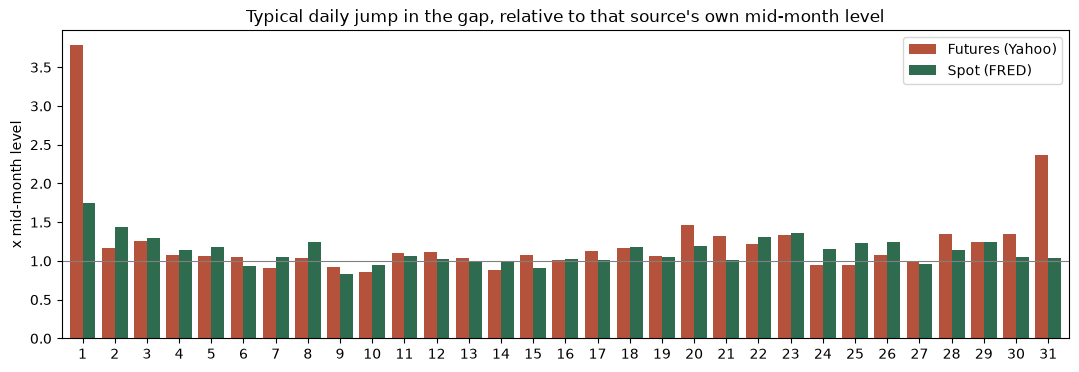

In [5]:
rel = {}
for src, px in pair_px.items():
    gap = np.log(px["Brent"]) - np.log(px["WTI"])
    jump = gap.diff().abs() * 1e4
    by_day = jump.groupby(jump.index.day).median()
    rel[src] = by_day / by_day.loc[6:15].mean()
ax = pd.DataFrame(rel).plot(kind="bar", figsize=(13, 4), width=0.8, color=["#B5523B", "#2E6B4F"], rot=0)
ax.axhline(1, color="grey", lw=0.8)
ax.set_title("Typical daily jump in the gap, relative to that source's own mid-month level")
ax.set_ylabel("x mid-month level"); plt.show()

## 5. Is the lead real on spot prices? (training period only)

Same cointegration test as Stage 3: build the gap on the training period, check it gets pulled back (t-stat below **−3.34**), and measure the **half-life** (days to close halfway).

If the futures' fast 21-day half-life was mostly the roll, the spot half-life should come out **noticeably longer**.

In [6]:
def fit_line(y, x):
    X = np.column_stack([np.ones(len(x)), x])
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ coef
    se = np.sqrt((resid @ resid) / (len(y) - 2) * np.linalg.inv(X.T @ X).diagonal())
    return coef, coef / se, resid

tie_rows = {}
for src, px in pair_px.items():
    train = np.log(px.loc[:SPLIT_DATE].iloc[:-1])
    (alpha, beta), _, gap = fit_line(train["Brent"].values, train["WTI"].values)
    (_, b_coef), (_, b_t), _ = fit_line(np.diff(gap), gap[:-1])
    tie_rows[src] = {
        "hedge ratio (beta)":  beta,
        "pull-back b":         b_coef,
        "t-stat of b":         b_t,
        "passes (t < -3.34)?": "yes" if b_t < -3.34 else "no",
        "half-life (days)":    -np.log(2) / np.log(1 + b_coef) if b_coef < 0 else np.inf,
    }
pd.DataFrame(tie_rows).T

,hedge ratio (beta),pull-back b,t-stat of b,passes (t < -3.34)?,half-life (days)
Futures (Yahoo),0.9987,-0.0330,-6.7789,yes,20.6306
Spot (FRED),1.0492,-0.0966,-11.7424,yes,6.8228


## 6. The Stage 3 strategy, unchanged

Same rules as Stage 3:
* Gap more than **2** wobbles too wide → sell Brent, buy WTI. Too narrow → the opposite.
* Close when the gap is back within **0.5** wobbles of normal.
* $\beta$ and the "normal gap" use **past data only**, and the past gap is rebuilt with today's $\beta$ (the stretching-ruler fix from Stage 3).
* Sized for 10% annual volatility, costs paid on both legs.

In [7]:
def make_pair_frame(px):
    df = pd.DataFrame(index=px.index)
    la, lb = np.log(px["Brent"]), np.log(px["WTI"])
    df["ret_a"], df["ret_b"] = px["Brent"].pct_change(), px["WTI"].pct_change()
    beta = (la.rolling(BETA_WINDOW).cov(lb) / lb.rolling(BETA_WINDOW).var()).shift(1)
    df["beta"] = beta
    df["gap"] = la - beta * lb
    m_a, m_b = la.rolling(Z_WINDOW).mean().shift(1), lb.rolling(Z_WINDOW).mean().shift(1)
    v_a, v_b = la.rolling(Z_WINDOW).var().shift(1),  lb.rolling(Z_WINDOW).var().shift(1)
    c_ab     = la.rolling(Z_WINDOW).cov(lb).shift(1)
    df["z"] = (df["gap"] - (m_a - beta * m_b)) / np.sqrt(v_a + beta**2 * v_b - 2 * beta * c_ab)
    gap_ret = df["ret_a"] - beta * df["ret_b"]
    df["size"] = (TARGET_VOL / np.sqrt(TRADING_DAYS) / gap_ret.rolling(20).std().shift(1)).clip(upper=MAX_LEVERAGE)
    return df.dropna()

def positions_from_z(z, entry=ENTRY_Z, exit_=EXIT_Z):
    pos, state = np.zeros(len(z)), 0
    for i, v in enumerate(z):
        if np.isnan(v):
            state = 0
        else:
            if (state == 1 and v > -exit_) or (state == -1 and v < exit_):
                state = 0
            if state == 0:
                state = -1 if v > entry else (1 if v < -entry else 0)
        pos[i] = state
    return pos

def run_pair(df, entry=ENTRY_Z, exit_=EXIT_Z, cost_mult=1.0, delay=0):
    out = df.copy()
    decided = positions_from_z(out["z"].values, entry, exit_)
    out["position"] = pd.Series(decided, index=out.index).shift(1 + delay).fillna(0)
    out["w_a"] =  out["position"] * out["size"]
    out["w_b"] = -out["position"] * out["size"] * out["beta"]
    turn_a = out["w_a"].diff().abs().fillna(out["w_a"].abs())
    turn_b = out["w_b"].diff().abs().fillna(out["w_b"].abs())
    out["cost"] = (turn_a * COST_BPS["Brent"] + turn_b * COST_BPS["WTI"]) / 1e4 * cost_mult
    out["net_ret"] = out["w_a"] * out["ret_a"] + out["w_b"] * out["ret_b"] - out["cost"]
    out["net_equity"] = (1 + out["net_ret"]).cumprod()
    return out

frames  = {src: make_pair_frame(px) for src, px in pair_px.items()}
results = {src: run_pair(df) for src, df in frames.items()}

## 7. Scorecard — futures vs spot, training vs unseen test

In [8]:
def t_stat(x):
    x = pd.Series(x).dropna()
    return x.mean() / (x.std() / np.sqrt(len(x))) if len(x) > 1 and x.std() > 0 else np.nan

def scorecard(r):
    ret, position = r["net_ret"], r["position"]
    years = len(ret) / TRADING_DAYS
    equity = (1 + ret).cumprod()
    sd = ret.std()
    direction = np.sign(position)
    opens = ((direction != 0) & (direction != direction.shift(1).fillna(0))).sum()
    return {
        "CAGR":               equity.iloc[-1] ** (1 / years) - 1,
        "Sharpe":             ret.mean() / sd * np.sqrt(TRADING_DAYS) if sd > 0 else np.nan,
        "Max drawdown":       (equity / equity.cummax() - 1).min(),
        "Win rate":           (ret[position != 0] > 0).mean(),
        "t-stat":             t_stat(ret),
        "Trades / year":      opens / years,
        "Avg days per trade": (direction != 0).sum() / opens if opens else np.nan,
        "Cost drag / year":   r["cost"].sum() / years,
    }

FMT = {"CAGR": "{:.1%}", "Max drawdown": "{:.1%}", "Win rate": "{:.1%}", "Cost drag / year": "{:.2%}",
       "Sharpe": "{:.2f}", "t-stat": "{:.2f}", "Trades / year": "{:.1f}", "Avg days per trade": "{:.1f}"}

cards = {}
for src, r in results.items():
    cards[(src, "training (to 2022)")] = scorecard(r.loc[:SPLIT_DATE].iloc[:-1])
    cards[(src, "TEST (2023 on)")]     = scorecard(r.loc[SPLIT_DATE:])
pd.DataFrame(cards).T.style.format(FMT, na_rep="—")

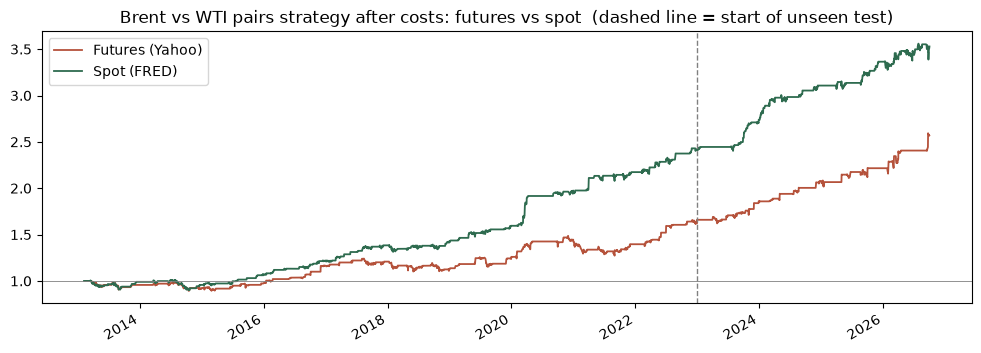

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))
for (src, r), c in zip(results.items(), ["#B5523B", "#2E6B4F"]):
    r["net_equity"].plot(ax=ax, color=c, lw=1.3, label=src)
ax.axvline(pd.Timestamp(SPLIT_DATE), color="grey", ls="--", lw=1)
ax.axhline(1, color="grey", lw=0.6)
ax.set_title("Brent vs WTI pairs strategy after costs: futures vs spot  (dashed line = start of unseen test)")
ax.legend(); ax.set_xlabel(""); plt.show()

## 8. The two Stage 3 checks, now on both versions

**When do trades open?** Random entries would put about 1/6 of trades in each slot. Bunching at days 1–5 and 21–25 is the roll's fingerprint.

**Where does the profit come from?** Trades opened mid-month (days 6–15, away from both swaps) vs near a swap. A real edge should make money in **both** windows.

In [10]:
def trade_table(r):
    direction = np.sign(r["position"])
    trade_id = ((direction != 0) & (direction != direction.shift(1).fillna(0))).cumsum()
    held = r.assign(trade_id=trade_id)[direction != 0]
    trades = held.groupby("trade_id").agg(opened=("net_ret", lambda x: x.index[0]), pnl=("net_ret", "sum"))
    trades["opened"] = pd.to_datetime(trades["opened"])
    return trades

bins = [0, 5, 10, 15, 20, 25, 31]
entry_days, by_window = {}, {}
for src, r in results.items():
    t = trade_table(r)
    entry_days[src] = pd.cut(t["opened"].dt.day, bins).value_counts().sort_index()
    t["window"] = np.where(t["opened"].dt.day.between(6, 15), "mid-month (days 6-15)", "near a roll (days 16-5)")
    by_window[src] = t.groupby("window")["pnl"].agg(["count", "mean", "sum"])

display(pd.DataFrame(entry_days).rename_axis("day of month opened"))
display(pd.concat(by_window).style.format({"mean": "{:.2%}", "sum": "{:.1%}"}))

,Futures (Yahoo),Spot (FRED)
day of month opened,,
"(0, 5]",30,18
"(5, 10]",4,20
"(10, 15]",8,17
"(15, 20]",12,23
"(20, 25]",19,19
"(25, 31]",13,16


## 9. Stress tests (test period, 2023 on)

Same as Stage 3: nearby entry levels, higher costs, one day late.

> **Watch the one-day-late column for spot.** If the two spot prices are recorded at different times of day, news after London closes shows up in WTI today but Brent tomorrow — the gap jumps, then "snaps back" the next day. That fake snap-back lasts one day, so **acting a day late removes it**. If spot only works when trading at the close, be suspicious.

In [11]:
stress = {}
for src, df in frames.items():
    test = lambda **kw: scorecard(run_pair(df, **kw).loc[SPLIT_DATE:])["Sharpe"]
    stress[src] = {
        "entry 1.5":          test(entry=1.5),
        "entry 2.0 (chosen)": test(entry=2.0),
        "entry 2.5":          test(entry=2.5),
        "0x costs":           test(cost_mult=0),
        "2x costs":           test(cost_mult=2),
        "3x costs":           test(cost_mult=3),
        "one day late":       test(delay=1),
    }
pd.DataFrame(stress).T.round(2)

,entry 1.5,entry 2.0 (chosen),entry 2.5,0x costs,2x costs,3x costs,one day late
Futures (Yahoo),1.7300,1.3800,1.3700,1.4900,1.2600,1.1400,0.7700
Spot (FRED),1.8900,1.5700,1.3800,1.6500,1.4800,1.4000,0.9200


## 10. Findings

* **Can you see the roll?** Yes. Compared with its own mid-month level, the Brent–WTI futures gap typically jumps 2.4× as much on the 31st and 3.8× on the 1st, when Brent swaps contracts, against 1.05× and 1.75× for spot prices. WTI's swap shows as a smaller bump on days 20–21 (1.47× and 1.33× in futures vs 1.2× and 1.0× in spot).

* **Is the lead still real on spot?** Yes, and stronger: t = −11.7 (futures −6.8), hedge ratio 1.05 (futures 1.00) and a half-life of 7 days against the futures' 21. The long-run Brent–WTI tie is not a futures artefact.

* **Does the edge survive on spot?** Yes. Spot earned 11.0% a year in the 2023–26 test period (Sharpe 1.57, t = 2.99, worst drawdown 4.8%), after a strong training period (Sharpe 1.24, t = 3.87). Futures were similar in the test period (Sharpe 1.38), so the roll distorted *when* the futures strategy traded rather than creating the whole edge.

* **Has the fingerprint gone?** Yes. Spot entries are spread evenly across the month (16–23 per five-day slot vs about 19 expected), against futures' bunching on days 1–5 (30 entries). Spot's mid-month trades are profitable (+0.54% each vs −0.28% for futures), though trades opened around the turn of the month still earn more (+1.48%), possibly because WTI spot partly tracks the futures expiry.

* **Is the spot result robust?** Yes. Test Sharpe was 1.38–1.89 across entry levels, 1.40 at triple costs, and 0.92 when trading one day late. The one-day-late result rules out the main alternative explanation — that spot's snap-back only comes from Brent and WTI being recorded at different times of day — though the drop from 1.57 to 0.92 suggests part of the edge may be.

**Caveats:** spot prices can't be traded directly; a real version would trade Brent and WTI futures for the *same delivery month* and roll both legs on the same day, which needs individual contract data. Profits come in steps, with a few large trades (e.g. early 2020) contributing a lot. And Brent vs WTI was the best of three pairs tested, so some of its edge may be selection luck.

### The project in one line
Daily mean reversion that looked strong in crypto fails in FX and commodities after costs — but the Brent–WTI spread snaps back reliably: after finding and removing a futures-roll artefact, spot prices still deliver a Sharpe of 1.57 on unseen 2023–26 data, and 0.92 trading a day late.

In [12]:
# ---- Export the numbers for the project page ----
import json

def weekly(equity):
    w = equity.resample("W-FRI").last().dropna()
    return [[d.strftime("%Y-%m-%d"), round(float(v), 4)] for d, v in w.items()]

def relative_jumps(px, how):
    gap = np.log(px["Brent"]) - np.log(px["WTI"])
    jump = gap.diff().abs() * 1e4
    by_day = jump.groupby(jump.index.day).agg(how)
    return [round(float(v), 3) for v in (by_day / by_day.loc[6:15].mean()).values]

export = {
    "split": SPLIT_DATE,
    "equity": {src: weekly(r["net_equity"]) for src, r in results.items()},
    "jumps": {
        "typical": {src: relative_jumps(px, "median") for src, px in pair_px.items()},
        "average": {src: relative_jumps(px, "mean") for src, px in pair_px.items()},
    },
}
with open("mean-reversion.json", "w") as f:
    json.dump(export, f, separators=(",", ":"))
print("Saved mean-reversion.json:", {k: len(v) for k, v in export["equity"].items()}, "weeks of equity")

Saved mean-reversion.json: {'Futures (Yahoo)': 712, 'Spot (FRED)': 713} weeks of equity
